# 📘 **Podem predir la qualifiació final?**
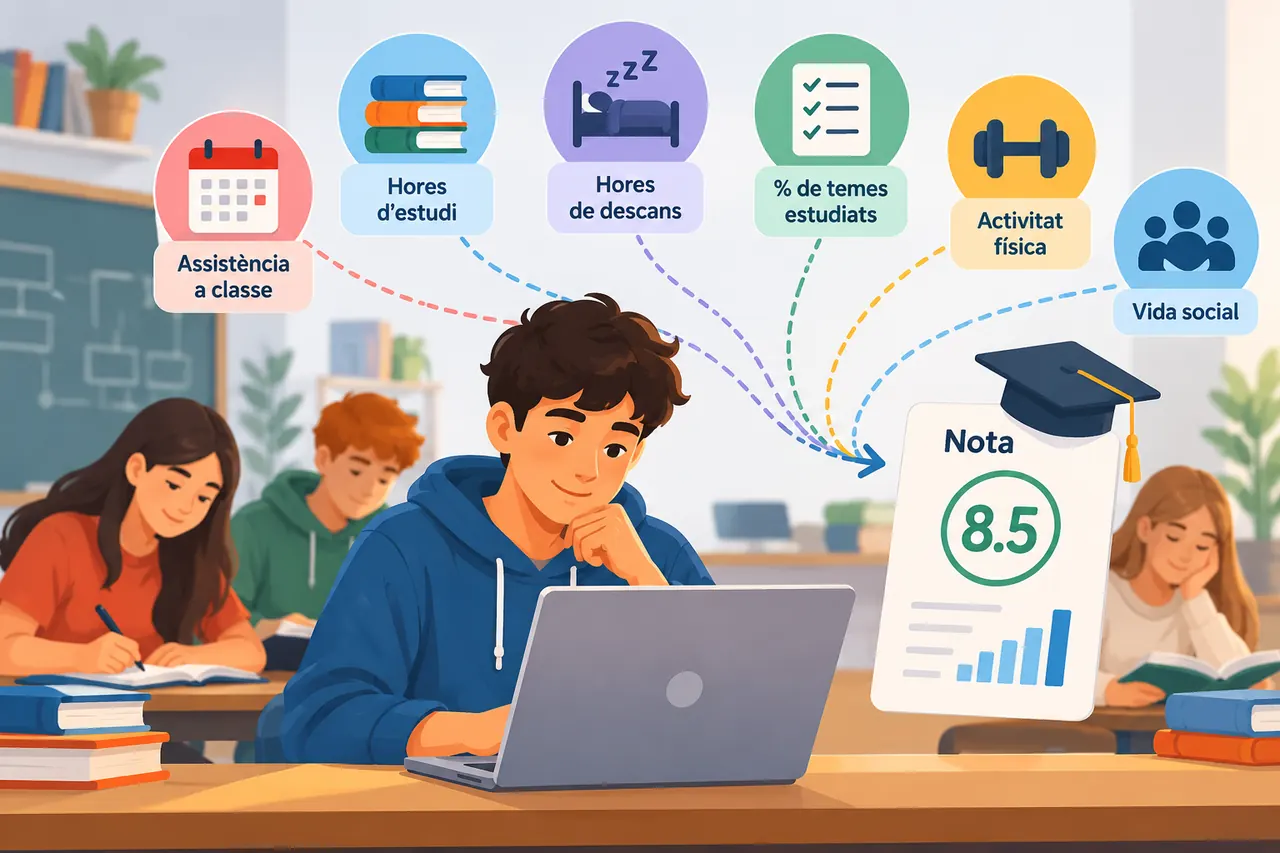

### **📚 02 Models Supervisats - Regressió lineal multivariable**  
##### 🗂️ M0572 Sistemes d'aprenentatge automàtic  
###### 👤 *Robert Ventura Vall-llovera*  

---


**🎯 Objectiu:** L'objectiu d'aquest Notebook és realitzar una regressió lineal multivariable per veure si podem predir la qualifiació final mitjançant  les característiques personals, familiars, acadèmiques i socials.


**📦 Datasets**
Les fonts de les dades ón registres de centres de secundària de Portual obtinguts mijançant qüestionaris i informes escolars ([UCI Student Performance, Cortez i Sivla, 2008](https://archive.ics.uci.edu/dataset/320/student+performance))

Atributs per als conjunts de dades student-mat.csv (curs de matemàtiques) i student-por.csv (curs de llengua portuguesa):
* `school`: escola de l'estudiant (binari: "GP" - Gabriel Pereira o "MS" - Mousinho da Silveira)
* `sex`: sexe de l'estudiant (binari: "F" - femení o "M" - masculí)
* `age`: edat de l'estudiant (numèric: de 15 a 22)
* `address`: tipus de domicili de l'estudiant (binari: "U" - urbà o "R" - rural)
* `famsize`: mida de la família (binari: "LE3" - 3 o menys, o "GT3" - més de 3)
* `Pstatus`: situació de convivència dels pares (binari: "T" - viuen junts o "A" - viuen separats)
* `Medu`: nivell educatiu de la mare (numèric: 0 - cap, 1 - educació primària (4t curs), 2 - del 5è al 9è curs, 3 - educació secundària o 4 - educació superior)
* `Fedu`: nivell educatiu del pare (numèric: 0 - cap, 1 - educació primària (4t curs), 2 - del 5è al 9è curs, 3 - educació secundària o 4 - educació superior)
* `Mjob`: feina de la mare (nominal: "teacher" (docent), "health" (relacionada amb la salut), "services" (serveis públics, p. ex. administració o policia), "at_home" (a casa) o "other" (altre))
* `Fjob`: feina del pare (nominal: "teacher" (docent), "health" (relacionada amb la salut), "services" (serveis públics, p. ex. administració o policia), "at_home" (a casa) o "other" (altre))
* `reason`: motiu per triar aquesta escola (nominal: "home" (proximitat a casa), "reputation" (reputació de l'escola), "course" (preferència pel curs) o "other" (altre))
* `guardian`: tutor legal de l'estudiant (nominal: "mother" (mare), "father" (pare) o "other" (altre))
* `traveltime`: temps de desplaçament de casa a l'escola (numèric: 1 - <15 min., 2 - de 15 a 30 min., 3 - de 30 min. a 1 hora, o 4 - >1 hora)
* `studytime`: temps d'estudi setmanal (numèric: 1 - <2 hores, 2 - de 2 a 5 hores, 3 - de 5 a 10 hores, o 4 - >10 hores)
* `failures`: nombre de suspensos anteriors (numèric: n si 1<=n<3, en cas contrari 4)
* `schoolsup`: suport educatiu addicional (binari: sí o no)
* `famsup`: suport educatiu familiar (binari: sí o no)
* `paid`: classes particulars de pagament sobre la matèria del curs (matemàtiques o portuguès) (binari: sí o no)
* `activities`: activitats extraescolars (binari: sí o no)
* `nursery`: ha assistit a l'escola bressol (binari: sí o no)
* `higher`: vol cursar estudis superiors (binari: sí o no)
* `internet`: accés a Internet a casa (binari: sí o no)
* `romantic`: té una relació sentimental (binari: sí o no)
* `famrel`: qualitat de les relacions familiars (numèric: d'1 - molt dolenta a 5 - excel·lent)
* `freetime`: temps lliure després de l'escola (numèric: d'1 - molt baix a 5 - molt alt)
* `goout`: sortir amb els amics (numèric: d'1 - molt baix a 5 - molt alt)
* `Dalc`: consum d'alcohol durant els dies laborables (numèric: d'1 - molt baix a 5 - molt alt)
* `Walc`: consum d'alcohol durant el cap de setmana (numèric: d'1 - molt baix a 5 - molt alt)
* `health`: estat de salut actual (numèric: d'1 - molt dolent a 5 - molt bo)
* `absences`: nombre d'absències escolars (numèric: de 0 a 93)

Aquestes notes estan relacionades amb la matèria del curs, matemàtiques o Portuguès:
* `G1`: nota del primer període (numèrica: de 0 a 20)
* `G2`: nota del segon període (numèrica: de 0 a 20)
* `G3`: nota final (numèrica: de 0 a 20, variable objectiu)

# 0\) Connexió Google Drive i importació llibreries principals


In [ ]:
#instal·lació de pandas
#! conda install pandas -y
# pip install pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from google.colab import drive

drive.mount('/content/drive')
#path = '/content/drive/'
os.chdir('/content/drive/MyDrive/Colab Notebooks/M0572-SistemesAprenentatgeAutomatic/datasets/')
os.getcwd()

RANDOM_STATE = 42

sns.set_theme() # Setting seaborn style

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1\) EDA i neteja mínima

Llegim el fitxer `student-mat.csv` **(Curs de Matemàtiques)**

In [ ]:
df = pd.read_csv("student/student-mat.csv", sep=';')
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [ ]:
df.shape

(395, 33)

In [ ]:
# Esborrem les files duplicades i si tenim algun G3 la variable predictora a NULL
df = df.drop_duplicates().dropna(subset=["G3"])

In [ ]:
df.shape

(395, 33)

In [ ]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,G3,studytime_1,studytime_2,studytime_3,studytime_4,parents_edu_mean,suport_sum,familia_mitjana_edu,log_absencies,progres_relatiu
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,6,0,1,0,0,4,1,4,1.945910,0.2000
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,6,0,1,0,0,1,1,1,1.609438,0.0000
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,10,0,1,0,0,1,2,1,2.397895,0.1429
3,GP,F,15,U,GT3,T,4,2,health,services,...,15,0,0,1,0,3,2,3,1.098612,-0.0667
4,GP,F,16,U,GT3,T,3,3,other,other,...,10,0,1,0,0,3,2,3,1.609438,0.6667


## Estudi de les variables i *Feature Engineering*


### Temps d'estudi `studytime`

Si mirem les 33 columnes veiem que la que pot tenir més pes és `studytime`. En funció del número d'hores dedicades a estudiar a la setmana, el sentit comú ens diu que aquella persona que estudia més hores les setamana té qualificacions més altes.

Recordem el valor del camp `studytime` no són les hores reals de cada estudiant sinó de 4 intervals:
* 1 - <2 hores
* 2 - de 2 a 5 hores
* 3 - de 5 a 10 hores
* 4 - >10 hores


In [ ]:
df[["studytime", "G3"]].head()

,studytime,G3
0,2,6
1,2,6
2,2,10
3,3,15
4,2,10


#### Fem un gràfic de barres i un boxplot per cada interval del temps d'estudi

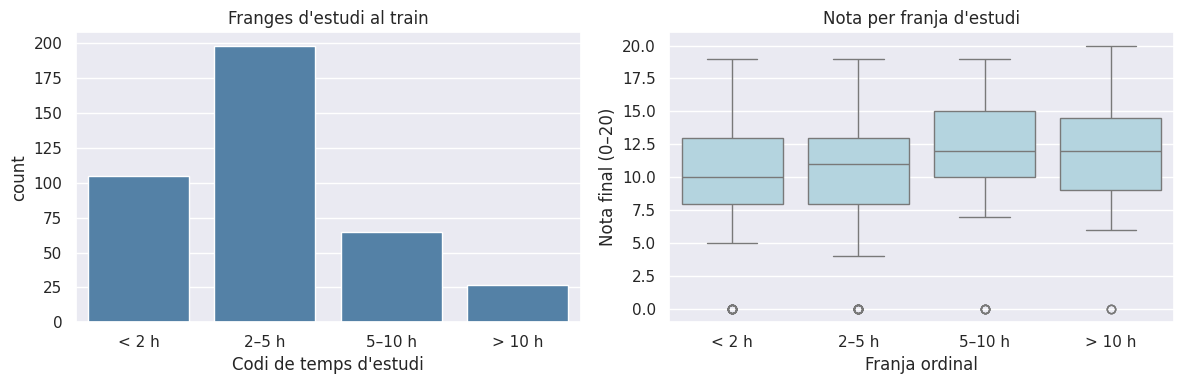

,count,mean,std,min,25%,50%,75%,max,IQR,Limit_inf,Limit_sup,Outliers_inf,Outliers_sup,Outliers,% Outliers
studytime,,,,,,,,,,,,,,,
1,105.0,10.05,4.96,0.0,8.0,10.0,13.0,19.0,5.0,0.50,20.50,13,0,13,12.38
2,198.0,10.17,4.22,0.0,8.0,11.0,13.0,19.0,5.0,0.50,20.50,16,0,16,8.08
3,65.0,11.40,4.64,0.0,10.0,12.0,15.0,19.0,5.0,2.50,22.50,6,0,6,9.23
4,27.0,11.26,5.28,0.0,9.0,12.0,14.5,20.0,5.5,0.75,22.75,3,0,3,11.11


In [ ]:
# Etiquetes de les quatre franges
etiquetes = {
    1: "< 2 h",
    2: "2–5 h",
    3: "5–10 h",
    4: "> 10 h"
}
ordre = list(etiquetes.keys())

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="studytime", ax=axs[0], color="steelblue")
axs[0].set(title="Franges d'estudi al train", xlabel="Codi de temps d'estudi")
sns.boxplot(data=df, x="studytime", y="G3", ax=axs[1], color="lightblue")
axs[1].set(title="Nota per franja d'estudi", xlabel="Franja ordinal", ylabel="Nota final (0–20)")

# Poso els labels de les hores d'estudi
for ax in axs:
    ax.set_xticks(range(len(ordre)))
    ax.set_xticklabels([etiquetes[x] for x in ordre])

plt.tight_layout(); plt.show()
#print("Correlació de Pearson al train:", round(entrenament["studytime"].corr(entrenament["G3"]), 3))

stats = df.groupby("studytime")["G3"].describe()

stats["IQR"] = stats["75%"] - stats["25%"]

# Límits inferior i superior (criteri de Tukey)
stats["Limit_inf"] = stats["25%"] - 1.5 * stats["IQR"]
stats["Limit_sup"] = stats["75%"] + 1.5 * stats["IQR"]

# Incorporar els límits a cada observació
df_aux = df[["studytime", "G3"]].join(
    stats[["Limit_inf", "Limit_sup"]],
    on="studytime"
)

# Identificar els outliers
df_aux["Outlier_inf"] = (
    (df_aux["G3"] < df_aux["Limit_inf"])
)

df_aux["Outlier_sup"] = (
    (df_aux["G3"] > df_aux["Limit_sup"])
)


# Comptar els outliers per cada franja
stats["Outliers_inf"] = df_aux.groupby("studytime")["Outlier_inf"].sum()
stats["Outliers_sup"] = df_aux.groupby("studytime")["Outlier_sup"].sum()
stats["Outliers"] = stats["Outliers_inf"] + stats["Outliers_sup"]

# Percentatge d'outliers respecte al total de la franja
stats["% Outliers"] = stats["Outliers"] / stats["count"] * 100

# Mostrar resultats
display(stats.round(2))



Mirant les gràfiques i la taula anterior podem dir:

*   No hi hauran outliers superior perqè els limits superiors són superiors a 20 i el valor màxim és 20.
*   No esborraria cap outlier en aquest context del problema perquè segur que hi ha alumnes que han estudiat molt i han tret un zero i també hi ha alumnes amb poques hores d'estudi que han tret molt bona nota.


Aquesta variable expressa un ordre natural: un alumne de la categoria 4 estudia més hores que un de la categoria 2, però **els valors numèrics no representen increments constants d'hores**.
Per tant, el millro és fer una tranformació One-Hot Encoding d'aquesta variable.



In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    drop=None, # first esborrem la primera categoria
    sparse_output=False, # Quan es True retorna una matriu SciPy
    dtype=int #Indiquem que volem un enter
)

encoded = encoder.fit_transform(df[["studytime"]])

# Convertim el resultat a DataFrame
df_encoded = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(["studytime"]),
    index=df.index
)

# Afegim les noves columnes i eliminem l'original
# No esborro l'original per si la necessitem
#df = pd.concat([df.drop(columns=["studytime"]), df_encoded], axis=1)
df = pd.concat([df, df_encoded], axis=1)

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,Walc,health,absences,G1,G2,G3,studytime_1,studytime_2,studytime_3,studytime_4
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,1,3,6,5,6,6,0,1,0,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,1,3,4,5,5,6,0,1,0,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,3,10,7,8,10,0,1,0,0
3,GP,F,15,U,GT3,T,4,2,health,services,...,1,5,2,15,14,15,0,0,1,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,2,5,4,6,10,10,0,1,0,0


### Nivell d'estudis familiar `Medu` i `Fedu`

Aquestes dues característiques contenen el mateix valor (0-4). Aporten el nivell d'estudi del pare i la mare de l'alumne.
És un valor numèric entre 0-4:
* 0 = cap
* 1 = educació primària (4t curs)
* 2 = del 5è al 9è curs
* 3 = educació secundària
* 4 - educació superior

Aquí ens podem plantejar tenir una característica que ens marqui el nivell educatiu familiar de l'alumne fen la mitjana.
Cal tenir en compte que aquest nou camp és extret d'una variable categorica ordinal i l'hem d'entendre que la mitjana no ésun nivell educatiu real sinó un interpretació.

In [ ]:
#Comprovem si algun dels dos camps està a null
df[["Medu", "Fedu"]].isna().sum()


,0
Medu,0
Fedu,0


In [ ]:

# Com que algun df["parents_edu_mean"] = (
#    df["Medu"] + df["Fedu"]
#) / 2
df["parents_edu_mean"] = df[
    ["Medu", "Fedu"]
].mean(axis=1).astype(int)
df


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,health,absences,G1,G2,G3,studytime_1,studytime_2,studytime_3,studytime_4,parents_edu_mean
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,6,5,6,6,0,1,0,0,4
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,4,5,5,6,0,1,0,0,1
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,10,7,8,10,0,1,0,0,1
3,GP,F,15,U,GT3,T,4,2,health,services,...,5,2,15,14,15,0,0,1,0,3
4,GP,F,16,U,GT3,T,3,3,other,other,...,5,4,6,10,10,0,1,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,4,11,9,9,9,0,1,0,0,2
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,3,14,16,16,1,0,0,0,2
392,MS,M,21,R,GT3,T,1,1,other,other,...,3,3,10,8,7,1,0,0,0,1
393,MS,M,18,R,LE3,T,3,2,services,other,...,5,0,11,12,10,1,0,0,0,2


### Suport acadèmic

Disposem de les tres variables binàries `schoolsup`, `famsup` i `paid`.

Podem pensar en crear una vairable anomenada suport que ens indiqui un nivell de suport sumant les tres vairables binàries.
Això ens podria dir si l'alumne rep suport i en quin nivell.

$$ tipus\_suport = schoolsup + famsup + paid $$


In [ ]:
# Mirem el tipus de dades de les variables.
df[["schoolsup","famsup","paid"]].dtypes


,0
schoolsup,object
famsup,object
paid,object


In [ ]:
df["schoolsup"].unique()

array(['yes', 'no'], dtype=object)

In [ ]:
df["famsup"].unique()

array(['no', 'yes'], dtype=object)

In [ ]:
df["paid"].unique()

array(['no', 'yes'], dtype=object)

In [ ]:
#Transofrmem aquestes variables "yes", "no" amb 0 i 1 i llavors les sumem
df["suport_sum"] = (
    df[["schoolsup", "famsup", "paid"]]
    .eq("yes")
    .sum(axis=1)
)
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,absences,G1,G2,G3,studytime_1,studytime_2,studytime_3,studytime_4,parents_edu_mean,suport_sum
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,6,5,6,6,0,1,0,0,4,1
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,4,5,5,6,0,1,0,0,1,1
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,10,7,8,10,0,1,0,0,1,2
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,15,14,15,0,0,1,0,3,2
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,6,10,10,0,1,0,0,3,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,11,9,9,9,0,1,0,0,2,2
391,MS,M,17,U,LE3,T,3,1,services,services,...,3,14,16,16,1,0,0,0,2,0
392,MS,M,21,R,GT3,T,1,1,other,other,...,3,10,8,7,1,0,0,0,1,0
393,MS,M,18,R,LE3,T,3,2,services,other,...,0,11,12,10,1,0,0,0,2,0


In [ ]:
# Transformem aquestes variables amb 0 i 1 i llavors les sumem.

In [ ]:
df["familia_mitjana_edu"] = df[
    ["Medu", "Fedu"]
].mean(axis=1).astype(int)
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,G1,G2,G3,studytime_1,studytime_2,studytime_3,studytime_4,parents_edu_mean,suport_sum,familia_mitjana_edu
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,5,6,6,0,1,0,0,4,1,4
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,5,6,0,1,0,0,1,1,1
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,7,8,10,0,1,0,0,1,2,1
3,GP,F,15,U,GT3,T,4,2,health,services,...,15,14,15,0,0,1,0,3,2,3
4,GP,F,16,U,GT3,T,3,3,other,other,...,6,10,10,0,1,0,0,3,2,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,9,9,9,0,1,0,0,2,2,2
391,MS,M,17,U,LE3,T,3,1,services,services,...,14,16,16,1,0,0,0,2,0,2
392,MS,M,21,R,GT3,T,1,1,other,other,...,10,8,7,1,0,0,0,1,0,1
393,MS,M,18,R,LE3,T,3,2,services,other,...,11,12,10,1,0,0,0,2,0,2


### Absències

El valor de les absències és un valor enter que va de 0 a 93.

En aquest sentit ens podríem preguntar si val la pena la tranformació d'aquesta característica i pensar que cada absència addicional no té el mateix valor sobre la nota. És a dir, podríem pensar que no és el mateix passar d'1 absència a 5 que de 20 a 25.

Encara que la diferència entre aquests dos alumnes és de 5 faltes d'assistència el primer l'haurà perjudicat més que el segon, perquè el segon ja anirà tant despenjat que la diferència de 5 dies no l'afecterà com en el primer cas.

Per fer això podem aplicar una funció logarítmica a la variable `absences` per obtenir les absències amb una corba en forma de logaritme

$$ log\_absences = ln(1 + absences) $$

In [ ]:
df["log_absencies"] = np.log(
    1 + df["absences"]
)
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,G2,G3,studytime_1,studytime_2,studytime_3,studytime_4,parents_edu_mean,suport_sum,familia_mitjana_edu,log_absencies
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,6,6,0,1,0,0,4,1,4,1.945910
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,6,0,1,0,0,1,1,1,1.609438
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,8,10,0,1,0,0,1,2,1,2.397895
3,GP,F,15,U,GT3,T,4,2,health,services,...,14,15,0,0,1,0,3,2,3,1.098612
4,GP,F,16,U,GT3,T,3,3,other,other,...,10,10,0,1,0,0,3,2,3,1.609438
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,9,9,0,1,0,0,2,2,2,2.484907
391,MS,M,17,U,LE3,T,3,1,services,services,...,16,16,1,0,0,0,2,0,2,1.386294
392,MS,M,21,R,GT3,T,1,1,other,other,...,8,7,1,0,0,0,1,0,1,1.386294
393,MS,M,18,R,LE3,T,3,2,services,other,...,12,10,1,0,0,0,2,0,2,0.000000


In [ ]:
##'''fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#
#sns.regplot(
#    data=df,
#    x="absences",
#    y="G3",
#    ax=axes[0]
#)
#
#sns.regplot(
#    data=df,
#    x="log_absencies",
#    y="G3",
#    ax=axes[1]
#)
#
#axes[0].set_title("Absències originals")
#axes[1].set_title("Absències transformades")

#plt.tight_layout()
#plt.show()

# 2\) Forward Selection

El **Forward Selection (selecció progressiva de variables)** és una tècnica de *Feature Selection* utilitzada en Machine Learning per identificar quines variables predictores aporten més informació al model.

Incorporar variables innecessàris pot augmentar la complexitat del model, dificultar-ne la interpretació i, en determinades situacions, provocar *overfitting*.

Exemple:

Tenim 3 característiques: *feature1, feature2, feature3*

$$ S_0=\varnothing $$

$$ S_0 \text{ representa el conjunt inicial de caractrístiques} $$

Iteració 1: Generam una regressió lineal simple amb cadascuna d'aquestes variables i s'avalua el model mitjançant una mètrica, MAE per exemple.
L'algorisme selecciona aquell model a on doni el millor valor de la mètrica.

$$ S_1=\{feature 2\} $$

Iteració 2: En el model generat anteriorment se generen 2 models afegint cadascuna de les característiques restants

$$ S_2=\{feature 2 , feature3\} $$

Aquset procés iteratiu continuarà fins que:
* Arribem al nombre de variables prefixat
* El model la millor no sigui suficient d'un llindar establert. per exemple 0.01 i si el model anterior versus el seguent no hi ha una millora que superi aquest 0.01 aturarem el procés.

In [ ]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'studytime_1',
       'studytime_2', 'studytime_3', 'studytime_4', 'parents_edu_mean',
       'suport_sum', 'familia_mitjana_edu', 'log_absencies',
       'progres_relatiu'],
      dtype='object')

In [ ]:
from sklearn.model_selection import train_test_split, PredefinedSplit

vars_indep = ['age','parents_edu_mean']
#'school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
#       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
#       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
#       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
#       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'
# 'parents_edu_mean', 'tipus_suport','suport', 'log_absencies', 'progres_relatiu' ,
var_dep = 'G3'

X = df[vars_indep].copy()
y = df[var_dep].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)


### Seleccionem les variables

In [ ]:
from sklearn.model_selection import KFold
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

selector = SequentialFeatureSelector(
    estimator=LinearRegression(),
    n_features_to_select="auto",
    direction="forward",
    scoring="neg_mean_absolute_error", #neg_mean_absolute_error,r2
    cv=kf,
    tol=0.01
)

selector.fit(X_train, y_train)

variables_seleccionades = X_train.columns[
    selector.get_support()
].tolist()

print("Nombre seleccionat:", len(variables_seleccionades))
print("Variables:", variables_seleccionades)

Nombre seleccionat: 1
Variables: ['G2']


* `n_features_to_select="auto"`: li indiquem quan deixa de seleccionar variables si està a **"auto"** i no hi ha definit el paràmetre `tol` seleccionarà aproximadametn la metitat de les característiques disponibles.
* `tol=0.01`: és la tolerància que volem que tingui la mètrica que utilitza per decidir si ha d'incoporar la següent variable.
* `scoring=neg_mean_absolute_error`: mètrica que utilitzarà per decidir quina variable incorporar. Scikit-lear segueix la convencio que les mètriques utilitzads amb el paràmetres `scoring`han de ser millors com més gran sigui el seu valor, per tant quan utilitzem el MAE negatiu, una millora de 0,01 en la puntuació equival a una reducció de 0,01 punts en el MAE. Valors més utilitzats:
  * `neg_mean_absolute_error`: MAE, minimitza l'error absolut mitjà
  * `neg_mean_squared_error`: MSE, minimitza l'error quadràtic mitjà
  * `neg_root_mean_squared_error`: RMSE, minimitza l'arrel de l'error quadràtic mitjà
  * `r2`: Coeficient R2, maximitza R2

## Entrenem el model

In [ ]:
# Una vegada sabem quines són les "millors" variables entrenem un model
X_train_sel = X_train[variables_seleccionades]
X_test_sel = X_test[variables_seleccionades]


# Crear i entrenar el model final
regressor = LinearRegression()

regressor.fit(X_train_sel, y_train)

# Consultar l'intercept
print("Intercept:", regressor.intercept_)

# Consultar els coeficients
coeficients = pd.DataFrame({
    "Variable": variables_seleccionades,
    "Coeficient": regressor.coef_
})

display(coeficients.round(4))

Intercept: -1.4936733199830226


,Variable,Coeficient
0,G2,1.1096


In [ ]:
# Una vegada sabem quines són les "millors" variables entrenem un model
X_train_sel = X_train[variables_seleccionades]
X_test_sel = X_test[variables_seleccionades]


# Crear i entrenar el model final
regressor = LinearRegression()

regressor.fit(X_train_sel, y_train)

# Consultar l'intercept
print("Intercept:", regressor.intercept_)

# Consultar els coeficients
coeficients = pd.DataFrame({
    "Variable": variables_seleccionades,
    "Coeficient": regressor.coef_
})

display(coeficients.round(4))

Intercept: -1.4936733199830226


,Variable,Coeficient
0,G2,1.1096


In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

# Prediccions sobre el conjunt de test
y_pred = regressor.predict(X_test_sel)

# Mètriques
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Resultats
resultats = pd.DataFrame({
    "Mètrica": ["MAE", "RMSE", "R²"],
    "Valor": [mae, rmse, r2]
})

display(resultats.round(3))

,Mètrica,Valor
0,MAE,1.209
1,RMSE,2.053
2,R²,0.794


## Visualització Resultats

In [ ]:
# 2. DataFrame de resultats
resultats = pd.DataFrame({
    "G3 real": y_test.to_numpy(),
    "G3 predit": y_pred
}, index=y_test.index)

# Calcular els errors
resultats["Residu"] = (
    resultats["G3 real"] - resultats["G3 predit"]
)

resultats["Error absolut"] = resultats["Residu"].abs()

# Identificador de l'observació original
resultats["Alumne"] = resultats.index.astype(str)

In [ ]:
resultats["Error absolut"].describe()

,Error absolut
count,79.000000
mean,1.208675
std,1.670513
min,0.041089
25%,0.287788
50%,0.739659
75%,1.445544
max,8.492960


# 3\) Backward Selection

El **Backward Selection**, a diferència de Forward Selection **comença amb totes les variables predictives i les va eliminant progressivament una a una a cada iteració**.

Per decidir quina ha d'eliminar, construeix diversos models, cadascun sense una de les variables actuals, i selecciona aquell que aconsegueix el millor resultat

Exemple:

Tenim 3 característiques: *feature1, feature2, feature3*

$$ S_0=\{feature1, feature 2 , feature3\} $$

$$ S_0 \text{ representa el conjunt inicial de caractrístiques} $$

Iteració 1: Generam una regressió lineal multiple amb totes les variables excepte una, s'avalua el model mitjançant una mètrica, MAE per exemple.
L'algorisme elimina la variable que, en retirar-la, deixa el model amb el menor error de validació.

Per exemple, si el MAE actual és de 2,74, eliminant la primera característica redueix la mètrica fina a 2,71. Per tant, és la millor eliminació.
<div align="center">

|Característica eliminada  | 	MAE resultant |	Variació MAE|
|--------------------------|----------------|-------------|
| feature1                 | **2,71**       | -0,03       |
| feature2                 | 2,74           | 0,00        |
| feature3                 | 2,78           | +0,04       |

</div>


$$ S_1=\{feature 1 , feature3\} $$

Igual que amb el Forward Selection podem finalitzar el procés prefixant un nombre finit de variables o una tolerància.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score

#vars_indep = df.columns.drop("G3").tolist()
vars_indep = ['age','parents_edu_mean']
var_dep = 'G3'

X = df[vars_indep].copy()
y = df[var_dep].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)



### Seleccionem les variables

In [ ]:
from sklearn.model_selection import KFold
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

selector = SequentialFeatureSelector(
    estimator=LinearRegression(),
    n_features_to_select="auto",
    direction="backward",
    scoring="neg_mean_absolute_error", #neg_mean_absolute_error,r2
    cv=kf,
    tol=-0.01
)

selector.fit(X_train, y_train)

# Variables seleccionades
variables_seleccionades = X_train.columns[
    selector.get_support()
].tolist()

# Variables eliminades
variables_eliminades = X_train.columns[
    ~selector.get_support()
].tolist()

print("Variables inicials:", len(vars_indep))
print("Variables seleccionades:", len(variables_seleccionades))
print("Seleccionades:", variables_seleccionades)
print("Eliminades:", variables_eliminades)

Variables inicials: 9
Variables seleccionades: 1
Seleccionades: ['G2']
Eliminades: ['studytime', 'age', 'parents_edu_mean', 'suport_sum', 'familia_mitjana_edu', 'log_absencies', 'progres_relatiu', 'G1']


## Entrenem el model

In [ ]:
# Una vegada sabem quines són les "millors" variables entrenem un model
X_train_sel = X_train[variables_seleccionades]
X_test_sel = X_test[variables_seleccionades]


# Crear i entrenar el model final
regressor = LinearRegression()

regressor.fit(X_train_sel, y_train)

# Consultar l'intercept
print("Intercept:", regressor.intercept_)

# Consultar els coeficients
coeficients = pd.DataFrame({
    "Variable": variables_seleccionades,
    "Coeficient": regressor.coef_
})

display(coeficients.round(4))

Intercept: -1.4936733199830226


,Variable,Coeficient
0,G2,1.1096


In [ ]:
# Una vegada sabem quines són les "millors" variables entrenem un model
X_train_sel = X_train[variables_seleccionades]
X_test_sel = X_test[variables_seleccionades]


# Crear i entrenar el model final
regressor = LinearRegression()

regressor.fit(X_train_sel, y_train)

# Consultar l'intercept
print("Intercept:", regressor.intercept_)

# Consultar els coeficients
coeficients = pd.DataFrame({
    "Variable": variables_seleccionades,
    "Coeficient": regressor.coef_
})

display(coeficients.round(4))

Intercept: -1.4936733199830226


,Variable,Coeficient
0,G2,1.1096


## Comprovem les mètriques

In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

# Prediccions sobre el conjunt de test
y_pred = regressor.predict(X_test_sel)

# Mètriques
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Resultats
resultats = pd.DataFrame({
    "Mètrica": ["MAE", "RMSE", "R²"],
    "Valor": [mae, rmse, r2]
})

display(resultats.round(3))

,Mètrica,Valor
0,MAE,1.209
1,RMSE,2.053
2,R²,0.794


## Visualització Resultats

In [ ]:
# 2. DataFrame de resultats
resultats = pd.DataFrame({
    "G3 real": y_test.to_numpy(),
    "G3 predit": y_pred
}, index=y_test.index)

# Calcular els errors
resultats["Residu"] = (
    resultats["G3 real"] - resultats["G3 predit"]
)

resultats["Error absolut"] = resultats["Residu"].abs()

# Identificador de l'observació original
resultats["Alumne"] = resultats.index.astype(str)

In [ ]:
resultats["Error absolut"].describe()

,Error absolut
count,79.000000
mean,1.208675
std,1.670513
min,0.041089
25%,0.287788
50%,0.739659
75%,1.445544
max,8.492960


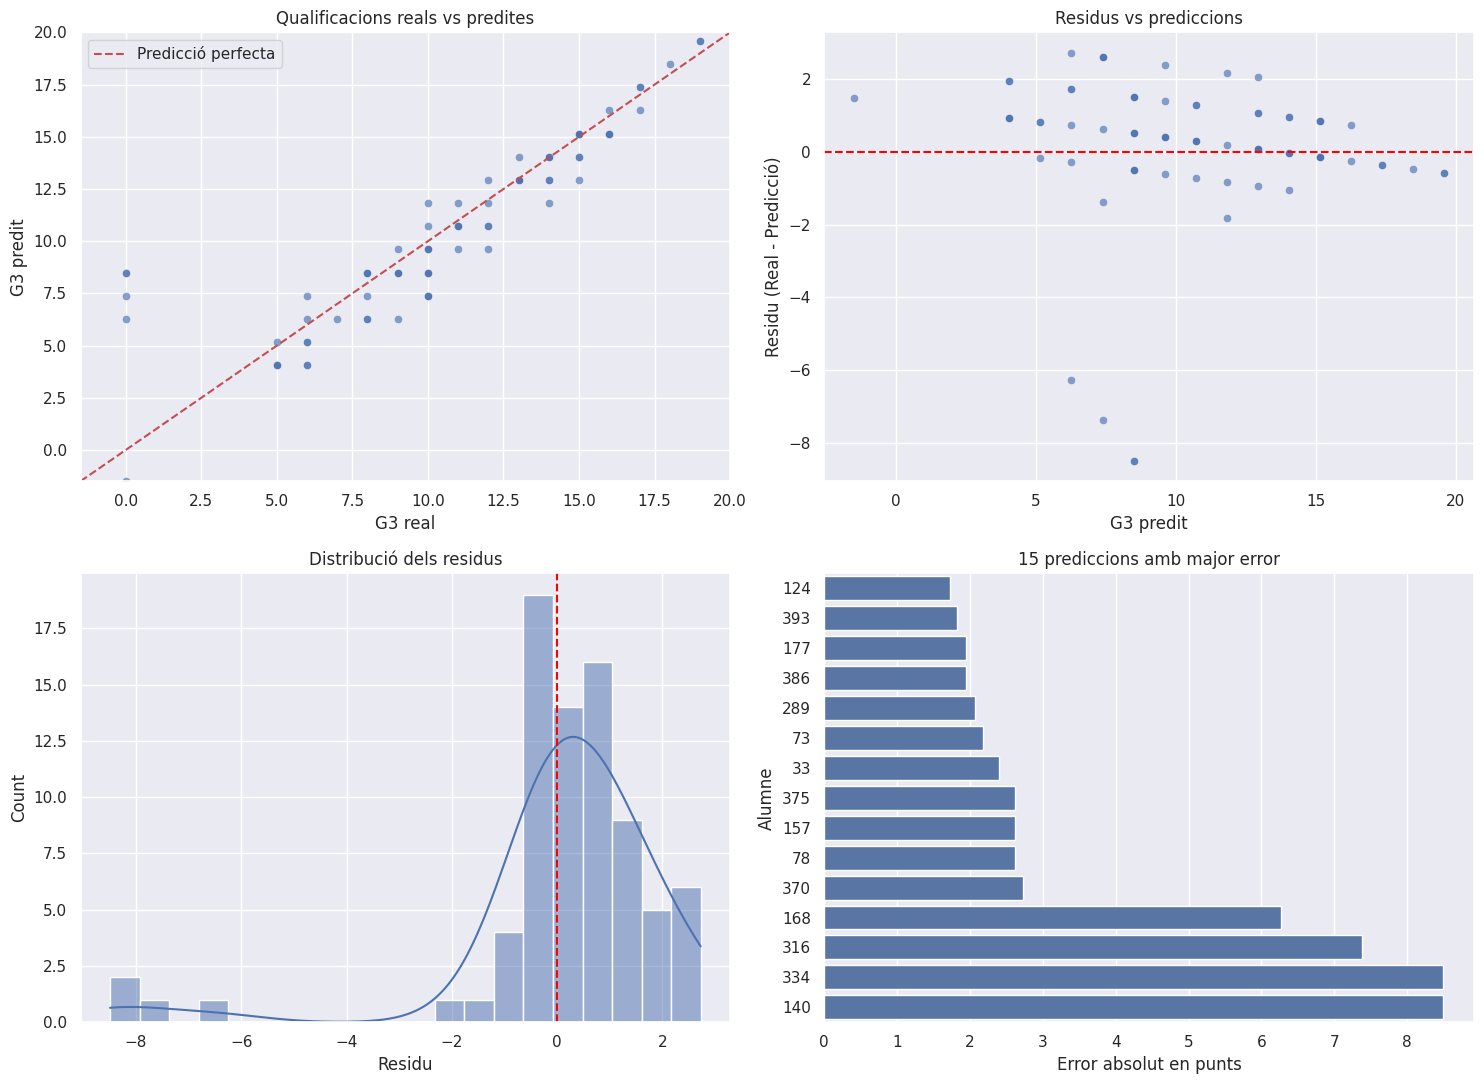

,G3 real,G3 predit,Residu,Error absolut,Alumne
334,0,8.49,-8.49,8.49,334
140,0,8.49,-8.49,8.49,140
316,0,7.38,-7.38,7.38,316
168,0,6.27,-6.27,6.27,168
370,9,6.27,2.73,2.73,370
78,10,7.38,2.62,2.62,78
375,10,7.38,2.62,2.62,375
157,10,7.38,2.62,2.62,157
33,12,9.60,2.40,2.40,33
73,14,11.82,2.18,2.18,73


In [ ]:

# 4. Crear els quatre gràfics
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# GRÀFIC 1: Valors reals vs prediccions
sns.scatterplot(
    data=resultats,
    x="G3 real",
    y="G3 predit",
    ax=axes[0, 0],
    alpha=0.65
)

limits = [
    min(0, resultats[["G3 real", "G3 predit"]].min().min()),
    max(20, resultats[["G3 real", "G3 predit"]].max().max())
]

axes[0, 0].plot(
    limits, limits,
    "r--",
    label="Predicció perfecta"
)

axes[0, 0].set_xlim(limits)
axes[0, 0].set_ylim(limits)
axes[0, 0].set_title("Qualificacions reals vs predites")
axes[0, 0].legend()

# GRÀFIC 2: Residus
sns.scatterplot(
    data=resultats,
    x="G3 predit",
    y="Residu",
    ax=axes[0, 1],
    alpha=0.65
)

axes[0, 1].axhline(0, color="red", linestyle="--")
axes[0, 1].set_title("Residus vs prediccions")
axes[0, 1].set_ylabel("Residu (Real - Predicció)")

# GRÀFIC 3: Distribució dels errors
sns.histplot(
    data=resultats,
    x="Residu",
    bins=20,
    kde=True,
    ax=axes[1, 0]
)

axes[1, 0].axvline(0, color="red", linestyle="--")
axes[1, 0].set_title("Distribució dels residus")

# GRÀFIC 4: Els 15 alumnes amb major error
pitjors = (
    resultats.nlargest(15, "Error absolut")
    .sort_values("Error absolut")
)

sns.barplot(
    data=pitjors,
    x="Error absolut",
    y="Alumne",
    ax=axes[1, 1]
)

axes[1, 1].set_title("15 prediccions amb major error")
axes[1, 1].set_xlabel("Error absolut en punts")

plt.tight_layout()
plt.show()

# 5. Mostrar les observacions amb més error
display(
    resultats.sort_values(
        "Error absolut", ascending=False
    ).head(15).round(2)
)

---


# 4\) Ús del `Pipeline`

El procés de construcció d'un model no consisteix únicament a entrenar un algorisme. Abans de fer les prediccions, habitualment cal preparar les dades, seleccionar característiques i, finalment, entrenat el model.

Per exemple en els apartats anteriors d'aquest notebook primer executàvem el `Sequential FeatureSelector`per identificar les característiques i posteriorment, consturíem i entrenàvem l'objecte `LinearRegresion` utilitzant nome´s les variables seleccionades.

**Scikit-learn té una eina anomenada `Pipeline`  que permet encadenar diferents operacions de tranformació de dades i entrenametn dins d'un únic objecte**

## Pipeline 1

In [ ]:
from sklearn.pipeline import Pipeline
model = Pipeline([
    (
        "selector",
        SequentialFeatureSelector(
            estimator=LinearRegression(),
            n_features_to_select="auto",
            direction="forward",
            scoring="neg_mean_absolute_error",
            cv=KFold(
                n_splits=5,
                shuffle=True,
                random_state=42
            ),
            tol=0.01
        )
    ),
    (
        "regressor",
        LinearRegression()
    )
])
model

Pipeline(steps=[('selector',
                 SequentialFeatureSelector(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                                           estimator=LinearRegression(),
                                           scoring='neg_mean_absolute_error',
                                           tol=0.01)),
                ('regressor', LinearRegression())])

In [ ]:
model.fit(X_train,y_train)

selector = model.named_steps["selector"]
regressor = model.named_steps["regressor"]

# Variables seleccionades
variables_seleccionades = X_train.columns[
    selector.get_support()
].tolist()

print("Variables seleccionades:")
print(variables_seleccionades)

print("Intercept:", regressor.intercept_)

# Coeficients de regressió
coeficients = pd.DataFrame({
    "Variable": variables_seleccionades,
    "Coeficient": regressor.coef_
})

display(coeficients.round(4))

Variables seleccionades:
['G2']
Intercept: -1.4936733199830226


,Variable,Coeficient
0,G2,1.1096


In [ ]:

from sklearn.model_selection import cross_validate

scores = cross_validate(
    model,
    X_train,
    y_train,
    cv=5,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    }
)

print("MAE:", -scores["test_MAE"].mean())
print("R²:", scores["test_R2"].mean())

MAE: 1.1364505591336045
R²: 0.8232075882736064


## Pipeline 2

Amb l'anterior Pipeline només encadenem un selector i un regressor, però Pipelines poden incorporar moltes altres operacions.

Una d'elles és el Preprocessament de les dades com pot ser One-Hot Encoding o estandaritzar les variables numèriques.

`ColumnTranformer`permet aplicar diferents preprocessaments a diferents grups de columnes i combinar-ne els resultats.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression

# Característiques del dataset
vars_categoriques = ["studytime"]

vars_numeriques = ["age", "parents_edu_mean", "suport_sum", "familia_mitjana_edu", "log_absencies", "progres_relatiu"]
vars_numeriques + vars_numeriques + ["G1","G2"]

# Preprocessament
preprocessament = ColumnTransformer([
    (
        "numeriques",
        StandardScaler(),
        vars_numeriques
    ),
    (
        "categoriques",
        OneHotEncoder(
            drop=None,
            handle_unknown="ignore"
        ),
        vars_categoriques
    )
])

# Pipeline complet
model = Pipeline([
    ("preprocessament", preprocessament),

    ("selector", SequentialFeatureSelector(
        estimator=LinearRegression(),
        n_features_to_select="auto",
        direction="forward",
        scoring="neg_mean_absolute_error",
        cv=kf,
        tol=0.01
    )),

    ("regressor", LinearRegression())
])

# Entrenar-ho tot
model.fit(X_train, y_train)

# Prediccions directes
y_pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))



MAE: 3.44802463844134
R²: 0.053368778184802124


In [ ]:
from sklearn.model_selection import train_test_split

vars_indep = ['studytime']
var_dep = 'G3'
X = df[vars_indep].copy()
y = df[var_dep].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

©️Llicència
===================================
Autor: Robert Ventura

[![](http://i.creativecommons.org/l/by-sa/4.0/88x31.png)](http://creativecommons.org/licenses/by-sa/4.0/)

Pots utilitzar lliurament aquest material, amb les següents condicions:

* Atribuir l'autoria d'aquest repositori.
* Si l'utilitzes i fas canvis, has de alliber-lo també sota la mateixa llicència.